### <font color = "gold"> Import les librairies requises

In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
 # Supprimer les warnings
 import warnings
 warnings.filterwarnings('ignore')

### <font color = "gold"> Importer et lire les données

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Importer les données
df = pd.read_csv('/content/drive/MyDrive/Machine Learning Licence 3/ML 4/wheat_seeds_dataset.csv')

**Nous avons ici des données de graines de blé. Chaque graine de blé est caractérisée par 7 variables morphologiques (issues de l'étude morphologique de chaque graine).**

In [5]:
# Afficher les données
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [6]:
# Dimension des données
df.shape

(199, 7)

In [7]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   area A                   199 non-null    float64
 1   perimeter                199 non-null    float64
 2   compactness              199 non-null    float64
 3   length of kernel         199 non-null    float64
 4   width of kernel          199 non-null    float64
 5   asymmetry coefficient    199 non-null    float64
 6   length of kernel groove  199 non-null    float64
dtypes: float64(7)
memory usage: 11.0 KB


In [8]:
# Décrire les données
df.describe()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
count,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,14.918744,14.595829,0.870811,5.643151,3.265533,3.699217,5.420653
std,2.919976,1.310445,0.023320,0.443593,0.378322,1.471102,0.492718
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000
25%,12.330000,13.470000,0.857100,5.267000,2.954500,2.570000,5.046000
50%,14.430000,14.370000,0.873400,5.541000,3.245000,3.631000,5.228000
75%,17.455000,15.805000,0.886800,6.002000,3.564500,4.799000,5.879000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.315000,6.550000


In [10]:
# Renommer les index
for i in range(len(df)):
  df.rename(index = {
      i:"Graine" + str(i+1)
  }, inplace = True)
# df.index = ['Graine' + str(i +1) for i in range(len(df))]
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
Graine1,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
Graine2,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
Graine3,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
Graine4,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
Graine5,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [11]:
# Matrice des données
x = df.values
x[:5]

array([[15.26  , 14.84  ,  0.871 ,  5.763 ,  3.312 ,  2.221 ,  5.22  ],
       [14.88  , 14.57  ,  0.8811,  5.554 ,  3.333 ,  1.018 ,  4.956 ],
       [14.29  , 14.09  ,  0.905 ,  5.291 ,  3.337 ,  2.699 ,  4.825 ],
       [13.84  , 13.94  ,  0.8955,  5.324 ,  3.379 ,  2.259 ,  4.805 ],
       [16.14  , 14.99  ,  0.9034,  5.658 ,  3.562 ,  1.355 ,  5.175 ]])

#### <font color = "gold"> Appliquer une ACP

In [21]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca = PCA(n_components=2)
# Matrice des 2 composantes
features_pca = pca.fit_transform(x)
# Dataframe
df_pca = pd.DataFrame(features_pca, columns = ['PC1', 'PC2'])

In [22]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(99.3)

### <font color = "gold"> Kmeans

In [14]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color = "bisque"> La méthode elbow(coude)

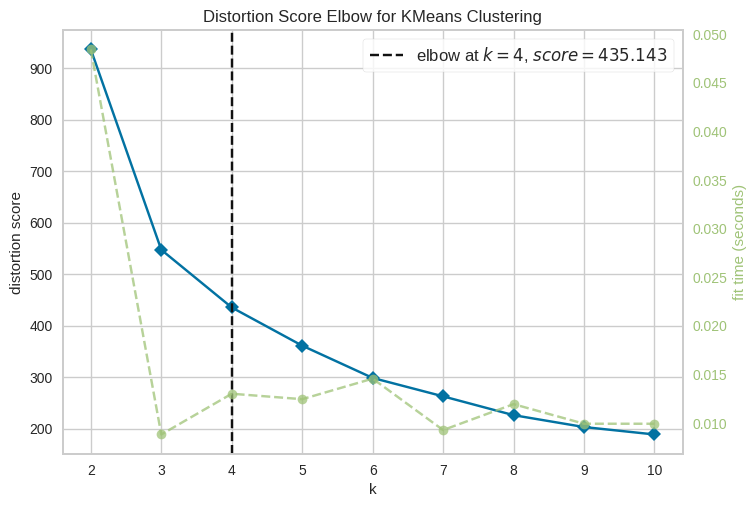

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [15]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

#### <font color = "bisque"> Appliquer Kmeans en utilisant le k optimal

In [16]:
# Initier le modèle
kmeans_model = KMeans(n_clusters = 4, init = 'random', max_iter = 500)
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=4)

#### <font color = "bisque"> Prédiction la partition

In [17]:
# Prediction de la partition(l'ensemble des classes) de X
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition

array([3, 3, 3, 3, 3, 3, 3, 1, 1, 1, 3, 3, 3, 3, 3, 0, 3, 3, 0, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 1, 3, 3, 3, 1, 1, 3, 0, 3, 3, 3, 1, 3, 3,
       3, 3, 3, 3, 3, 1, 3, 3, 3, 3, 3, 3, 3, 3, 0, 0, 0, 3, 3, 3, 3, 0,
       1, 1, 1, 2, 1, 1, 1, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0,
       0], dtype=int32)

In [19]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

,count
0,69
3,54
2,47
1,29


In [20]:
# Diagramme en barre du nombre d'observations dans chaque
import plotly.express as px
fig = px.bar(x = val.index, y = val.values ,color = val.index.astype(str))
fig.show()

#### <font color = "bisque"> Visualiser les classes prédictes par Kmeans

In [23]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PC1', y = 'PC2', color = kmeans_partition.astype(str))
fig.show()

<font color = "bisque">Indice de silhouette value de la partition du Kmeans

In [24]:
# Importer silhouette score
from sklearn.metrics import silhouette_score
# Indice de Silhouette value
sil_kmeans = silhouette_score(x, kmeans_partition)
print(f"Silhouette score : {sil_kmeans }")

Silhouette score : 0.41822883561631463


In [25]:
kmeans_partition == 0

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
        True, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True,  True,  True, False, False,
       False, False,  True, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,

In [26]:
# Les graines de chaque classes
clusters_names = []
for i in range(4):
  clusters_names.append(list(df.index[kmeans_partition == i]))

In [31]:
# Afficher les graines de la classe 0
print(clusters_names[3])

['Graine1', 'Graine2', 'Graine3', 'Graine4', 'Graine5', 'Graine6', 'Graine7', 'Graine11', 'Graine12', 'Graine13', 'Graine14', 'Graine15', 'Graine17', 'Graine18', 'Graine20', 'Graine21', 'Graine22', 'Graine23', 'Graine24', 'Graine25', 'Graine26', 'Graine27', 'Graine28', 'Graine29', 'Graine30', 'Graine32', 'Graine33', 'Graine34', 'Graine37', 'Graine39', 'Graine40', 'Graine41', 'Graine43', 'Graine44', 'Graine45', 'Graine46', 'Graine47', 'Graine48', 'Graine49', 'Graine51', 'Graine52', 'Graine53', 'Graine54', 'Graine55', 'Graine56', 'Graine57', 'Graine58', 'Graine62', 'Graine63', 'Graine64', 'Graine65', 'Graine160', 'Graine171', 'Graine191']


# Compléments : CAH, comparaison et déploiement

### <font color='gold'> CAH

In [ ]:
# Fonctions de visualisation (réutilisées pour la CAH)
New_df = df_pca

def bar_plot(val):
    fig = px.bar(x=val.index.astype(str), y=val.values, color=val.index.astype(str), text_auto=True,
                 labels={'x': 'Classe', 'y': 'Effectif', 'color': 'Classe'})
    fig.show()

def scatter_plot(New_df, Pred):
    fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str), labels={'color': 'Classe'})
    fig.show()

In [ ]:
# Importer linkage, dendrogram et fcluster
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt

# Matrice des liaisons (critère de Ward, adapté à des données standardisées)
Z = linkage(x, 'ward')

# Dendrogramme tronqué aux 30 dernières fusions (lisible même avec beaucoup d'individus)
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10, show_contracted=True)
plt.title("Dendrogramme (CAH, critère de Ward)")
plt.xlabel("Classes regroupées (effectif entre parenthèses)")
plt.ylabel("Distance")
plt.show()

In [ ]:
# Indice de silhouette de la CAH pour chaque nombre de classes
resultats_cah = []
for k in range(2, 9):
    part = fcluster(Z, k, criterion='maxclust') - 1
    resultats_cah.append({'k': k, 'silhouette': silhouette_score(x, part)})
sil_cah_par_k = pd.DataFrame(resultats_cah)
px.line(sil_cah_par_k, x='k', y='silhouette', markers=True).show()
sil_cah_par_k

In [ ]:
# Nombre de classes retenu : meilleur indice de silhouette entre 3 et 6 classes
# (à remplacer par une valeur lue sur le dendrogramme si besoin, ex : k_cah = 3)
k_cah = int(sil_cah_par_k[sil_cah_par_k['k'].between(3, 6)].sort_values('silhouette').iloc[-1]['k'])
print("Nombre de classes retenu pour la CAH :", k_cah)

from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters=k_cah, linkage='ward')
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
cah_partition[:100]

In [ ]:
# Nombre d'observations dans chaque classe
val1 = pd.Series(cah_partition).value_counts().sort_index()
print(val1)

# Diagramme en barres et visualisation des classes
bar_plot(val1)
scatter_plot(New_df, cah_partition)

# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print(f"Silhouette score CAH : {sil_cah:.4f}")

### <font color='gold'> Comparaison K-means / CAH

In [ ]:
# Comparaison des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x=Model_Names, y=sil, color=Model_Names, text_auto='.4f',
             labels={'x': 'Modèle', 'y': 'Silhouette score'})
fig.show()

In [ ]:
# Sélection automatique du meilleur modèle (silhouette la plus élevée)
if sil_kmeans >= sil_cah:
    meilleur_nom = 'KMEANS'
    partition_finale = kmeans_partition
else:
    meilleur_nom = 'CAH'
    partition_finale = cah_partition
print("Meilleur modèle :", meilleur_nom)

### <font color='gold'> Déploiement du meilleur modèle

In [ ]:
# Ici les données n'ont pas été transformées avant le clustering : le prétraitement est l'identité
from sklearn.preprocessing import FunctionTransformer
preprocess = FunctionTransformer()
colonnes = list(df.columns)

In [ ]:
from scipy.spatial.distance import cdist

# Centroïdes des classes du meilleur modèle (dans l'espace transformé)
classes = np.unique(partition_finale)
centroides = np.array([x[partition_finale == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
# `nouvel_individu` = liste des valeurs, dans l'ordre des colonnes de `colonnes`
def predire_classe(nouvel_individu):
    ligne = pd.DataFrame([nouvel_individu], columns=colonnes)
    z = preprocess.transform(ligne)
    return classes[cdist(z, centroides).argmin()]

In [ ]:
# Test rapide
print("Classe prédite          :", predire_classe(df.iloc[0].tolist()))
print("Classe réelle du modèle :", partition_finale[0])

#### <font color='teal'> Interpréter les classes

In [ ]:
# Profil moyen de chaque classe
profil = df.groupby(partition_finale).mean().round(2)
profil['effectif'] = pd.Series(partition_finale).value_counts().sort_index().values
profil

**À faire :** lis le tableau ci-dessus et remplace les noms par défaut par un nom qui décrit vraiment chaque groupe de graines (ex : « grosses graines allongées », « petites graines compactes »...).

In [ ]:
# Noms des classes : à personnaliser d'après le profil ci-dessus
noms_classes = {int(c): f"Groupe {c}" for c in classes}
noms_classes

### <font color='gold'> Sauvegarde du modèle pour l'application Streamlit

In [ ]:
import joblib

colonnes = list(df.columns)

bundle = {
    'nom_modele': meilleur_nom,
    'source': 'Jeu de données vu en cours (wheat_seeds_dataset.csv)',
    'colonnes': colonnes,
    'preprocess': preprocess,
    'centroides': centroides,
    'classes': classes,
    'noms_classes': noms_classes,
    'minimum': df.min().to_dict(),
    'maximum': df.max().to_dict(),
    'mediane': df.median().to_dict(),
}
joblib.dump(bundle, 'wheat_clustering.joblib')
print('Modèle sauvegardé dans wheat_clustering.joblib')

# Dans Colab, pour récupérer le fichier :
# from google.colab import files
# files.download('wheat_clustering.joblib')